# 09 — Hasil, Ranking, Perbandingan dengan Drift, dan Figur Gaya Jurnal

Menggabungkan **10 ML + 11 DL = 21 model** × 5 horizon × 2 setup = **210 hasil**. Drift dilaporkan sebagai benchmark terpisah (bukan salah satu dari 21 model).

Keluaran utama:
- `tabel_hasil_final.csv` (MAE/RMSE/sMAPE/MAPE + `pct_vs_drift`: **positif = model lebih baik dari Drift**), `ranking_model.csv`, `ringkasan_model.csv`;
- `metrik_return.csv`: metrik bebas-skala (RMSE/MAE di ruang return, R²oos terhadap Drift, rasio simpangan baku, korelasi, akurasi arah);
- `wakil_model.json`: tiga model wakil **otomatis** (DPformer, DL baseline terbaik, ML terbaik) yang dipakai SHAP (notebook 11) dan analisis tambahan (14–16);
- figur gaya Fig. 4–7 jurnal acuan, untuk kedua setup.

Ranking memakai **MAE uji** yang ditetapkan setelah seluruh pemilihan hiperparameter selesai tanpa melihat uji. Pemilihan "wakil terbaik" bersifat **deskriptif pasca-evaluasi** (menentukan model mana yang dijelaskan/diuji ulang), bukan tuning.

In [1]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK)
from src import analysis as A, plots as P, stats as S
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, RUNS, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    """Simpan figur (PNG + PDF) ke outputs/figures lalu tampilkan."""
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from src import runners as R
from src.pipeline import drift_h
H_CURVE = 20 if 20 in HORIZONS else max(HORIZONS)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


## 1. Kumpulkan seluruh hasil valid

In [2]:
ml = R.read_runs(RUNS, SETUPS, ML_MODELS, HORIZONS, rev=ML_REV, data_hash=DATA_HASH)
dl = R.read_runs(RUNS, SETUPS, DL_MODELS, HORIZONS, data_hash=DATA_HASH)
kol = ['setup', 'model', 'horizon', 'MAE', 'RMSE', 'sMAPE', 'MAPE', 'test_n']
dfres = pd.concat([ml[kol], dl[kol]], ignore_index=True)
expected = len(ALL_MODELS) * len(HORIZONS) * len(SETUPS)
print(f'Valid: {len(dfres)} / {expected}')
assert len(dfres) == expected, 'Semua 21 model harus selesai sebelum ranking final.'
for h in HORIZONS:                      # semua model dievaluasi pada baris uji yang sama per horizon
    vals = dfres.loc[dfres.horizon == h, 'test_n'].unique()
    assert len(vals) == 1, f'test_n tidak konsisten pada h={h}'
    print(f'h={h:>2}: test_n = {vals[0]}')
print('[OK] test_n identik antar 21 model.')

Valid: 210 / 210
h= 1: test_n = 864
h= 5: test_n = 864
h=10: test_n = 863
h=20: test_n = 861
h=30: test_n = 859
[OK] test_n identik antar 21 model.


## 2. Ranking MAE (per setup × horizon) dan ringkasan

In [3]:
drb = pd.read_csv(os.path.join(RES, 'drift_benchmark.csv'))
drift_mae = drb.set_index('horizon')['MAE']
dfres['pct_vs_drift'] = 100 * (dfres.horizon.map(drift_mae) - dfres.MAE) / dfres.horizon.map(drift_mae)   # positif = lebih baik dari Drift
dfres['rank'] = dfres.groupby(['setup', 'horizon'])['MAE'].rank(method='min')
dfres = dfres.sort_values(['setup', 'horizon', 'rank']).reset_index(drop=True)
dfres.to_csv(os.path.join(RES, 'tabel_hasil_final.csv'), index=False)
dfres.to_csv(os.path.join(RES, 'ranking_model.csv'), index=False)

ringkasan = (dfres.groupby('model')
             .agg(mean_rank=('rank', 'mean'), mean_MAE=('MAE', 'mean'), mean_RMSE=('RMSE', 'mean'),
                  mean_pct_vs_drift=('pct_vs_drift', 'mean'), n_lebih_baik_dari_drift=('pct_vs_drift', lambda x: int((x > 0).sum())),
                  wins=('rank', lambda x: int((x == 1).sum())))
             .sort_values(['mean_rank', 'mean_MAE']).reset_index())
ringkasan.to_csv(os.path.join(RES, 'ringkasan_model.csv'), index=False)
print('pct_vs_drift > 0  => MAE model LEBIH RENDAH daripada Drift pada horizon tersebut.')
display(ringkasan.round(3))

pct_vs_drift > 0  => MAE model LEBIH RENDAH daripada Drift pada horizon tersebut.


,model,mean_rank,mean_MAE,mean_RMSE,mean_pct_vs_drift,n_lebih_baik_dari_drift,wins
0,adaboost,2.8,45131.170,68348.621,2.394,10,4
1,rf,6.1,45450.538,70507.418,1.213,7,1
2,elasticnet,6.3,46018.008,71414.547,0.756,8,0
3,gru_att,7.8,46306.854,71974.581,0.244,7,0
4,extra_trees,8.3,45901.562,70848.516,0.377,7,0
5,lightgbm,8.4,46273.259,71861.264,0.334,8,1
6,lstm_att,8.7,46254.722,71816.743,0.254,7,0
7,patchtst,8.8,46160.014,71654.125,0.328,7,2
8,xgboost,8.9,46222.629,71862.038,0.317,8,0
9,transformer,9.8,47155.678,73416.487,-1.112,5,1


In [4]:
# Model terbaik per (setup, horizon) dan selisihnya terhadap Drift
terbaik = dfres.loc[dfres.groupby(['setup', 'horizon']).MAE.idxmin(), ['setup', 'horizon', 'model', 'MAE', 'pct_vs_drift']].reset_index(drop=True)
terbaik['n_model_lebih_baik_dari_drift'] = [int(((dfres.setup == r.setup) & (dfres.horizon == r.horizon) & (dfres.pct_vs_drift > 0)).sum()) for r in terbaik.itertuples()]
terbaik.to_csv(os.path.join(RES, 'model_terbaik_per_horizon.csv'), index=False)
display(terbaik.round(3))
print('Porsi hasil (dari 210) yang MAE-nya lebih rendah dari Drift:', f"{(dfres.pct_vs_drift > 0).mean() * 100:.0f}%")

,setup,horizon,model,MAE,pct_vs_drift,n_model_lebih_baik_dari_drift
0,multivariat,1,lightgbm,13189.686,0.434,3
1,multivariat,5,transformer,29495.097,1.973,9
2,multivariat,10,adaboost,41032.937,3.870,15
3,multivariat,20,adaboost,59958.027,4.757,12
4,multivariat,30,patchtst,81287.050,2.432,12
5,univariat,1,patchtst,13169.609,0.585,4
6,univariat,5,svr,29707.583,1.267,10
7,univariat,10,adaboost,41069.137,3.785,12
8,univariat,20,adaboost,58692.484,6.768,15
9,univariat,30,rf,80636.865,3.213,16


Porsi hasil (dari 210) yang MAE-nya lebih rendah dari Drift: 51%


## 3. Metrik bebas-skala (ruang return) dan akurasi arah

Harga Antam naik ≈3× di periode uji, sehingga MAE/RMSE dalam rupiah didominasi 2025–2026. Di ruang **return h-hari** (`R_h = harga(i+h)/harga(i) − 1`, sama dengan target latih) metrik tidak bergantung level harga. `R2oos_vs_drift = 1 − MSE_model/MSE_Drift` (Campbell–Thompson): positif = lebih baik dari Drift. `std_ratio` ≈ 0 berarti prediksi hampir konstan.

In [5]:
mt = A.metrics_return_table(RES, p, SETUPS, ALL_MODELS, HORIZONS)
assert len(mt) == expected
mt.to_csv(os.path.join(RES, 'metrik_return.csv'), index=False)
print('Median R2oos terhadap Drift per (setup, horizon):')
display(mt.pivot_table(index='setup', columns='horizon', values='R2oos_vs_drift', aggfunc='median').round(4))
print('Jumlah model (dari 21) dengan R2oos > 0:')
display(mt.assign(pos=mt.R2oos_vs_drift > 0).pivot_table(index='setup', columns='horizon', values='pos', aggfunc='sum').astype(int))

Median R2oos terhadap Drift per (setup, horizon):


horizon,1,5,10,20,30
setup,,,,,
multivariat,-0.0192,0.0036,0.0176,-0.0052,-0.0001
univariat,-0.0065,-0.0025,0.0046,0.0132,0.0069


Jumlah model (dari 21) dengan R2oos > 0:


horizon,1,5,10,20,30
setup,,,,,
multivariat,6,11,17,9,10
univariat,7,8,15,17,15


## 4. Model wakil otomatis (DPformer, DL baseline terbaik, ML terbaik)

Aturan (deterministik, tertulis sebelum melihat hasil): **peringkat rata-rata MAE di dalam kelompok** pada seluruh 10 kondisi (2 setup × 5 horizon); pemutus seri = rata-rata `pct_vs_drift` (lebih besar lebih baik), lalu nama model. DPformer selalu dipilih.

In [6]:
rep = A.pick_representatives(dfres, DL_MODELS, ML_MODELS)
rep['tabel_dl'].to_csv(os.path.join(RES, 'ranking_kelompok_dl.csv'), index=False)
rep['tabel_ml'].to_csv(os.path.join(RES, 'ranking_kelompok_ml.csv'), index=False)
wakil = {'dpformer': rep['dpformer'], 'dl': rep['dl'], 'ml': rep['ml'],
         'kriteria': 'peringkat rata-rata MAE dalam kelompok (2 setup x horizon); seri: rata-rata pct_vs_drift; DPformer tetap',
         'protocol': PROTOCOL}
with open(os.path.join(RES, 'wakil_model.json'), 'w', encoding='utf-8') as f:
    json.dump(wakil, f, indent=1)
print('Wakil terpilih:', {k: wakil[k] for k in ('dpformer', 'dl', 'ml')})
print('\n10 DL baseline (tanpa DPformer) — 5 teratas:')
display(rep['tabel_dl'].head(5).round(3))
print('10 ML — 5 teratas:')
display(rep['tabel_ml'].head(5).round(3))
sel = rep['tabel_dl'].mean_rank.values, rep['tabel_ml'].mean_rank.values
print(f'Selisih peringkat rata-rata juara vs peringkat-2: DL {sel[0][1] - sel[0][0]:.2f} | ML {sel[1][1] - sel[1][0]:.2f} '
      '(selisih kecil = hampir seri; pemilihan wakil tidak boleh ditafsirkan sebagai "jauh lebih baik")')

Wakil terpilih: {'dpformer': 'dpformer', 'dl': 'gru_att', 'ml': 'adaboost'}

10 DL baseline (tanpa DPformer) — 5 teratas:


,model,mean_rank,wins,mean_MAE,mean_pct_vs_drift
0,gru_att,3.6,1,46306.854,0.244
1,lstm_att,3.7,1,46254.722,0.254
2,patchtst,4.0,2,46160.014,0.328
3,lstm,4.8,0,46464.850,-0.012
4,transformer,4.9,3,47155.678,-1.112


10 ML — 5 teratas:


,model,mean_rank,wins,mean_MAE,mean_pct_vs_drift
0,adaboost,1.5,6,45131.170,2.394
1,rf,3.5,2,45450.538,1.213
2,elasticnet,3.7,0,46018.008,0.756
3,extra_trees,4.7,0,45901.562,0.377
4,lightgbm,4.7,1,46273.259,0.334


Selisih peringkat rata-rata juara vs peringkat-2: DL 0.10 | ML 2.00 (selisih kecil = hampir seri; pemilihan wakil tidak boleh ditafsirkan sebagai "jauh lebih baik")


## 5. Figur gaya jurnal (Fig. 4–6 Bao et al.), kedua setup

- `fig_hasil_<setup>`: (a) kurva prediksi h=20 vs aktual (DPformer + dua wakil + Drift), (b) heatmap RMSE (warna = % terhadap Drift), (c) MAE bertumpuk antar-horizon, (d) MAPE;
- `fig_perbaikan_<setup>`: MAE per horizon dan perbaikan % DPformer terhadap setiap model lain;
- `fig_panel_<setup>_h<h>`: (a) scatter level harga DPformer, (b) scatter return DPformer (dengan σ prediksi/σ aktual dan ρ), (c) diagram Taylor di ruang return untuk 21 model, (d) MAE dan (e) MAPE terurut.

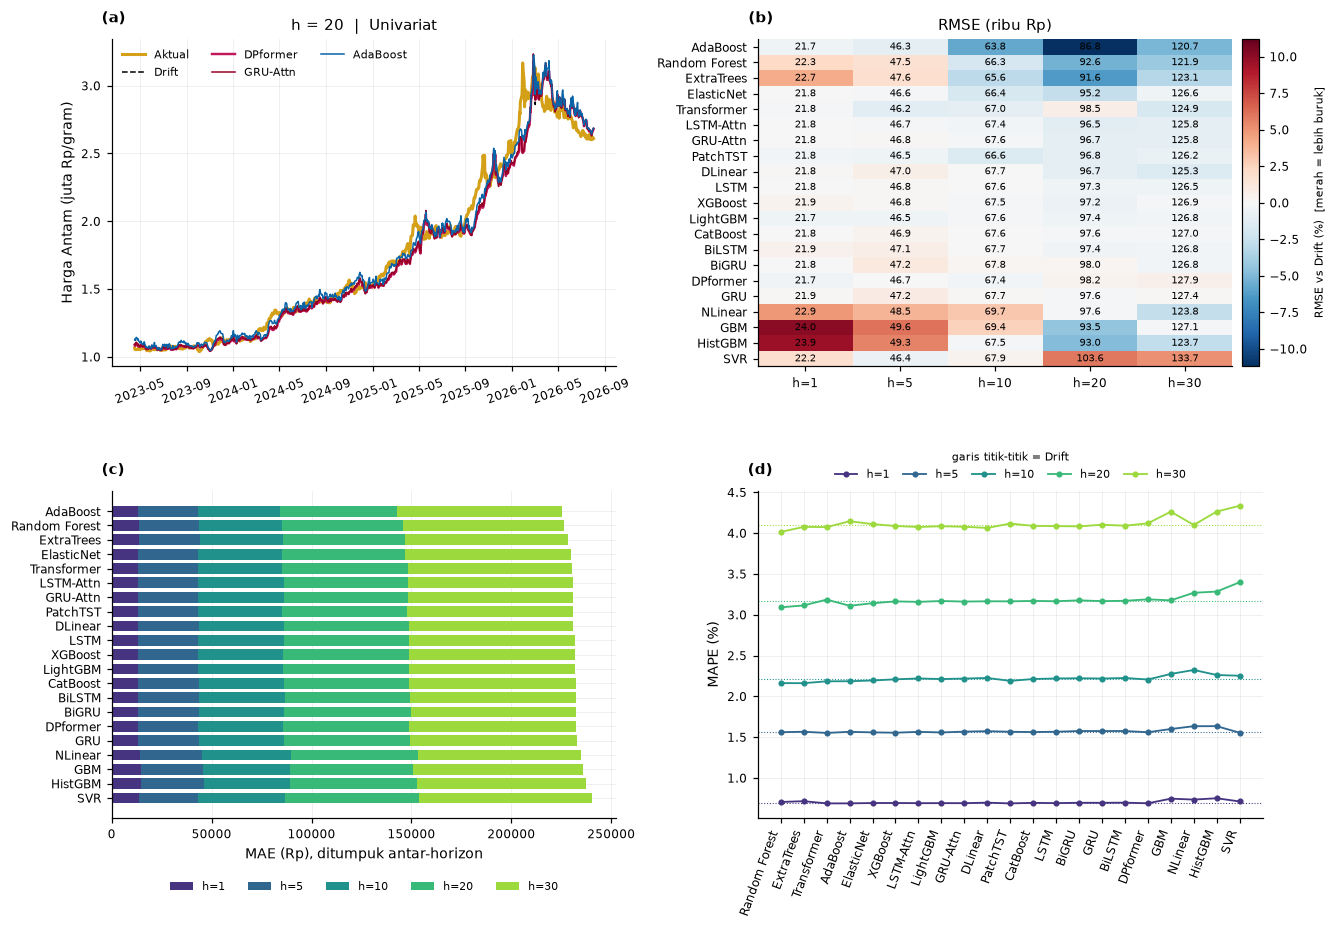

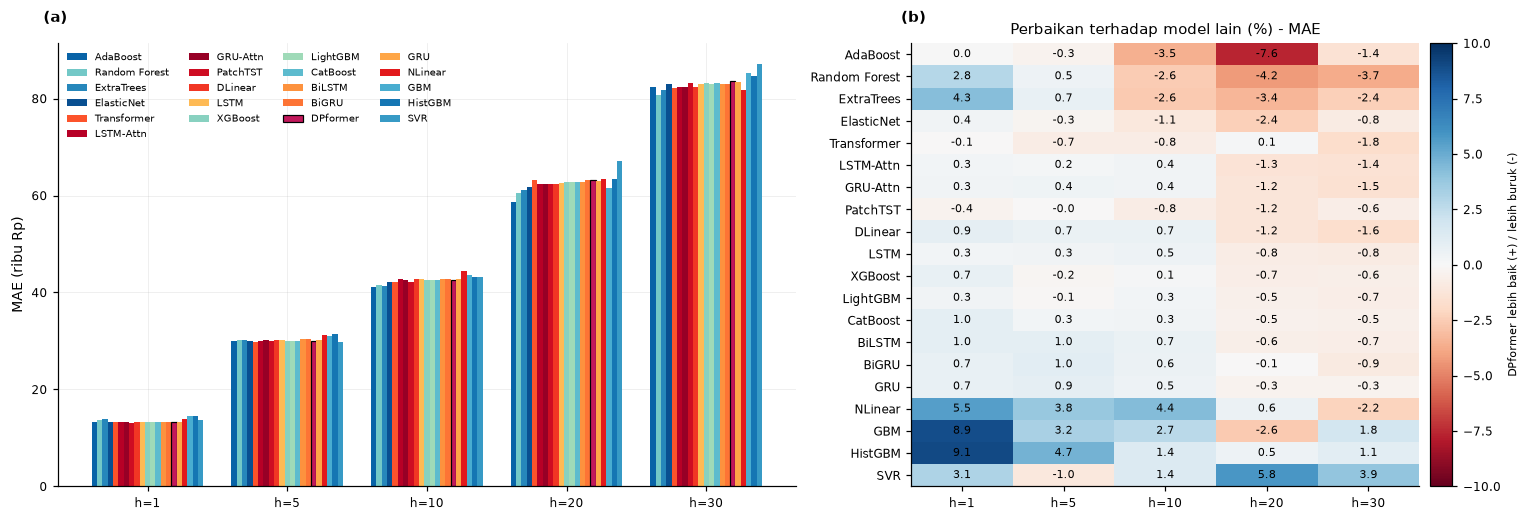

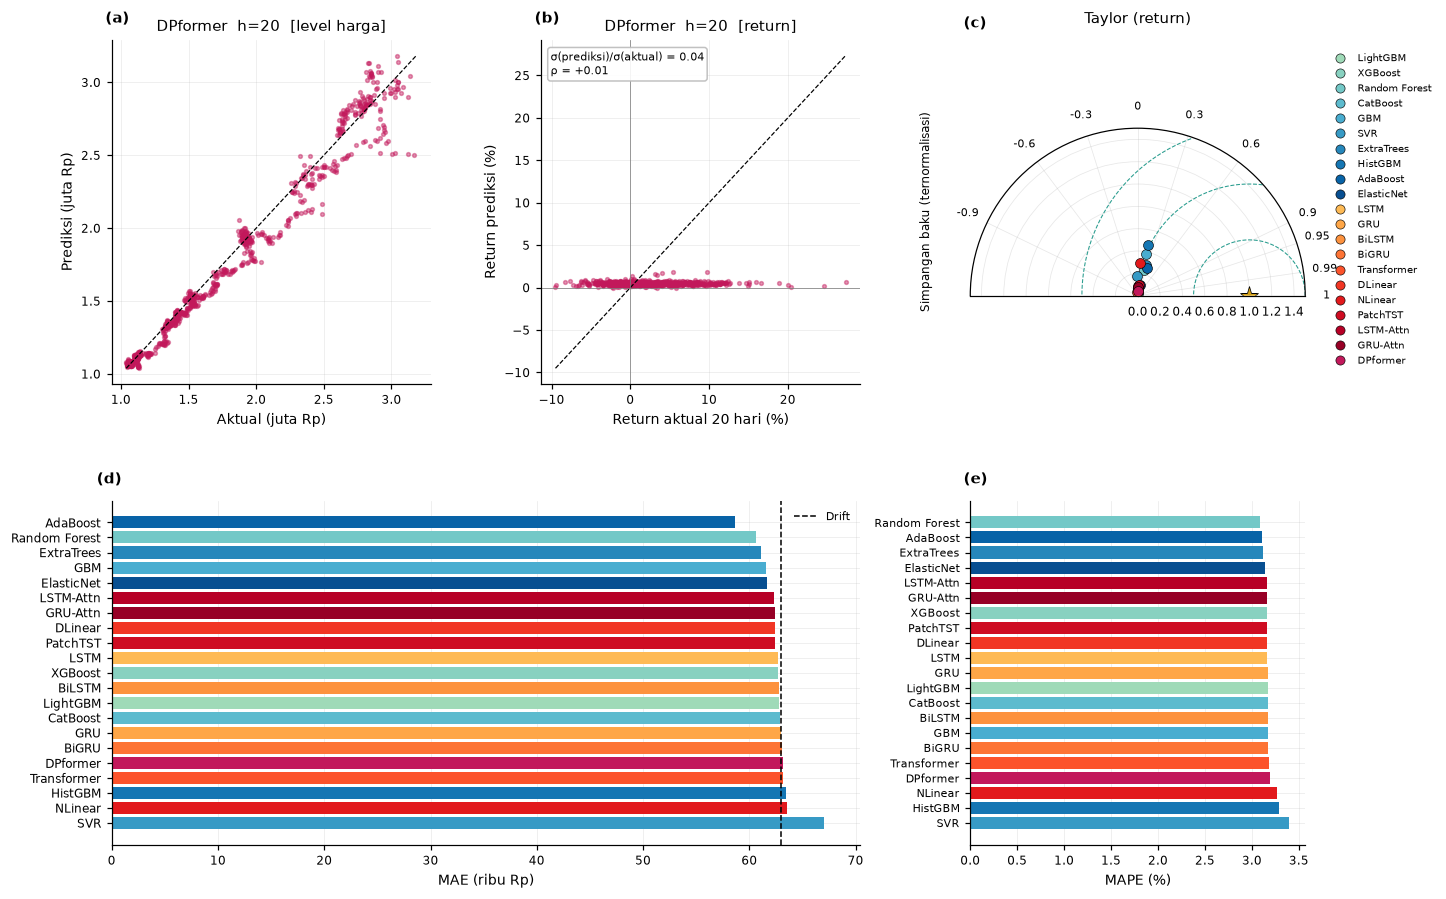

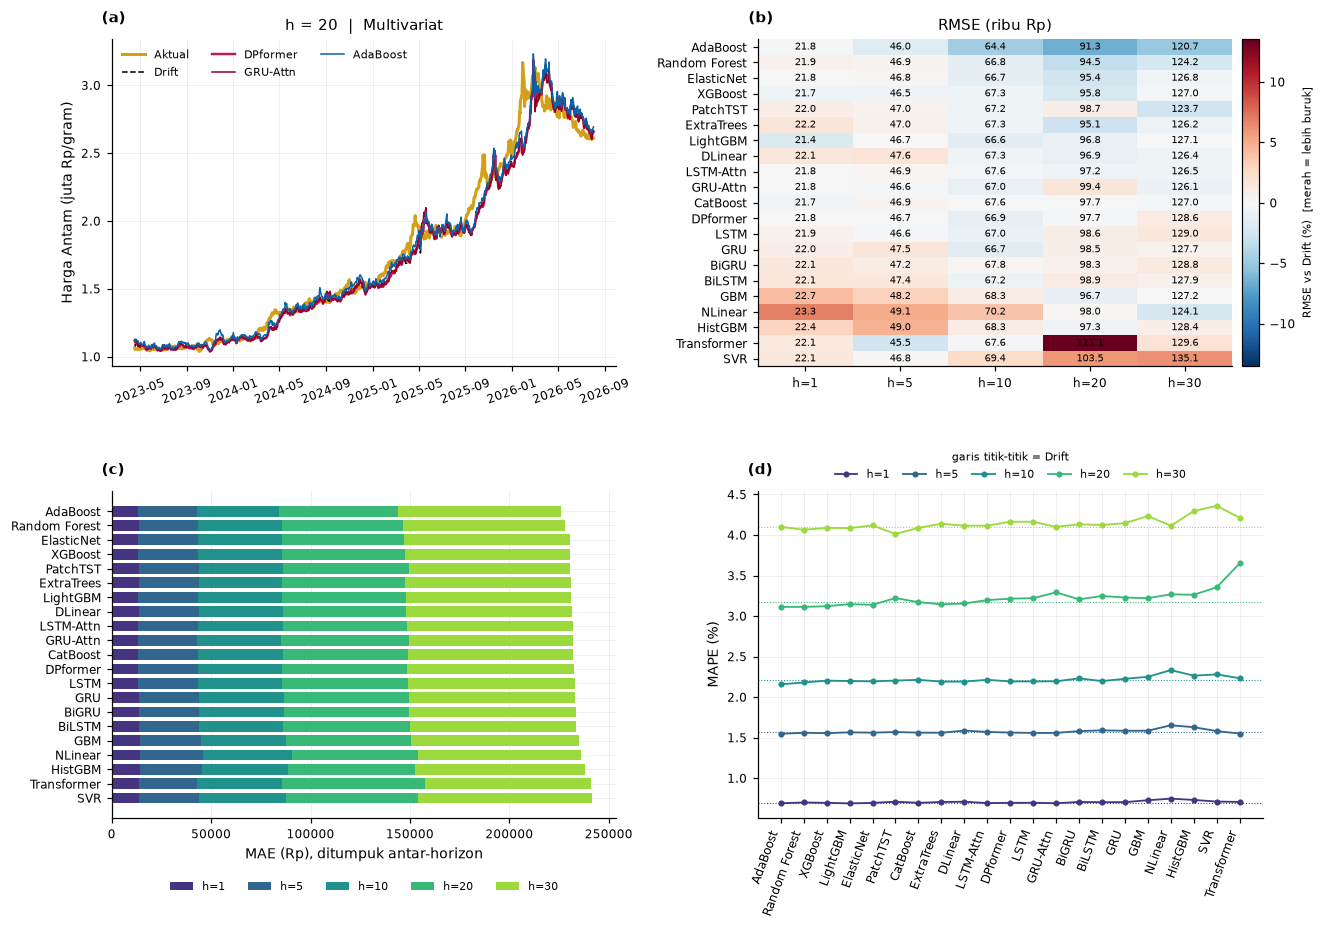

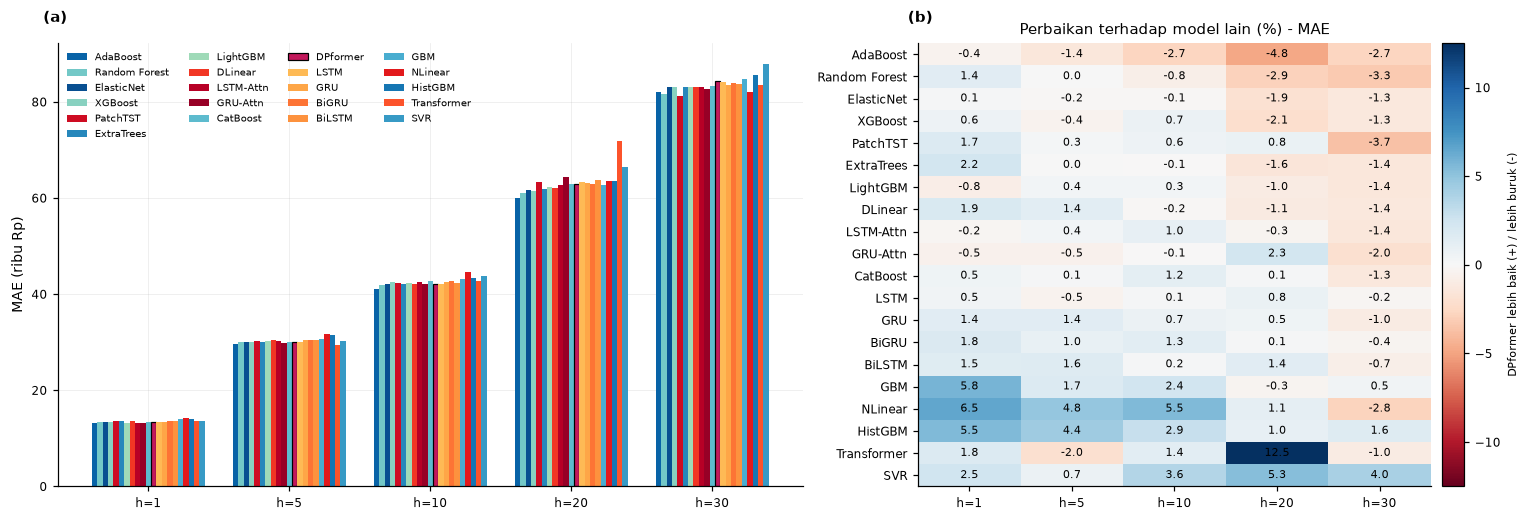

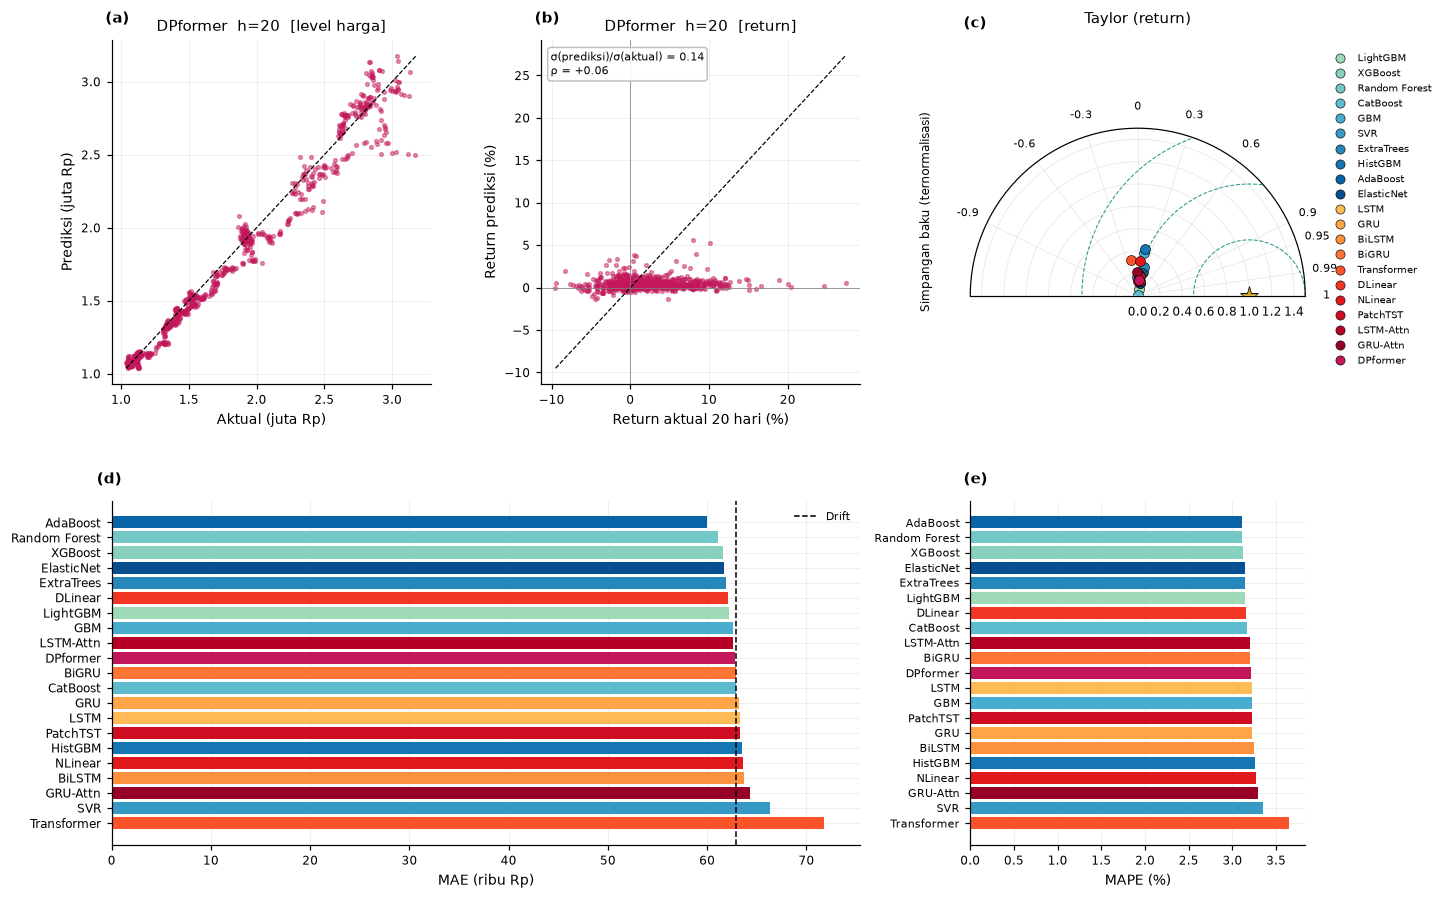

In [7]:
fr = {h: A.drift_frame(p, h) for h in HORIZONS}
tab_ = dfres.copy()
tab_['drift_MAE'] = tab_.horizon.map(drift_mae)
reps3 = [wakil['dpformer'], wakil['dl'], wakil['ml']]

for setup in SETUPS:
    curves = {'Aktual': fr[H_CURVE].y_true, 'drift': fr[H_CURVE].y_pred}
    for m in reps3:
        curves[m] = A.read_pred(RES, setup, m, H_CURVE).y_pred
    fig = P.fig_results_composite(dfres, curves, drb[drb.horizon.isin(HORIZONS)], setup, HORIZONS, H_CURVE)
    simpan(fig, f'fig_hasil_{setup}')
    fig, imp = P.fig_improvement(dfres, setup, HORIZONS)
    imp.round(2).to_csv(os.path.join(RES, f'perbaikan_dpformer_{setup}.csv'))
    simpan(fig, f'fig_perbaikan_{setup}')
    for h in HORIZONS:
        preds = {m: A.attach(A.read_pred(RES, setup, m, h), fr[h]) for m in ALL_MODELS}
        fig = P.fig_panel_h(preds, fr[h], tab_, setup, h)
        if h == H_CURVE:
            simpan(fig, f'fig_panel_{setup}_h{h}')
        else:
            P.save_fig(fig, f'fig_panel_{setup}_h{h}', FIGS)
            plt.close(fig)

### Jendela peristiwa (Fig. 7 jurnal)

Tiga jendela dipilih **objektif dari harga** (bukan dari kinerja model) dan tidak tumpang-tindih: kenaikan harga terbesar, volatilitas tertinggi, dan periode paling sideways, dalam 120 hari di periode uji.

                    nama      mulai      akhir
0               Sideways 2023-04-26 2023-10-11
1          Reli terbesar 2025-08-14 2026-01-29
2  Volatilitas tertinggi 2026-01-30 2026-07-17


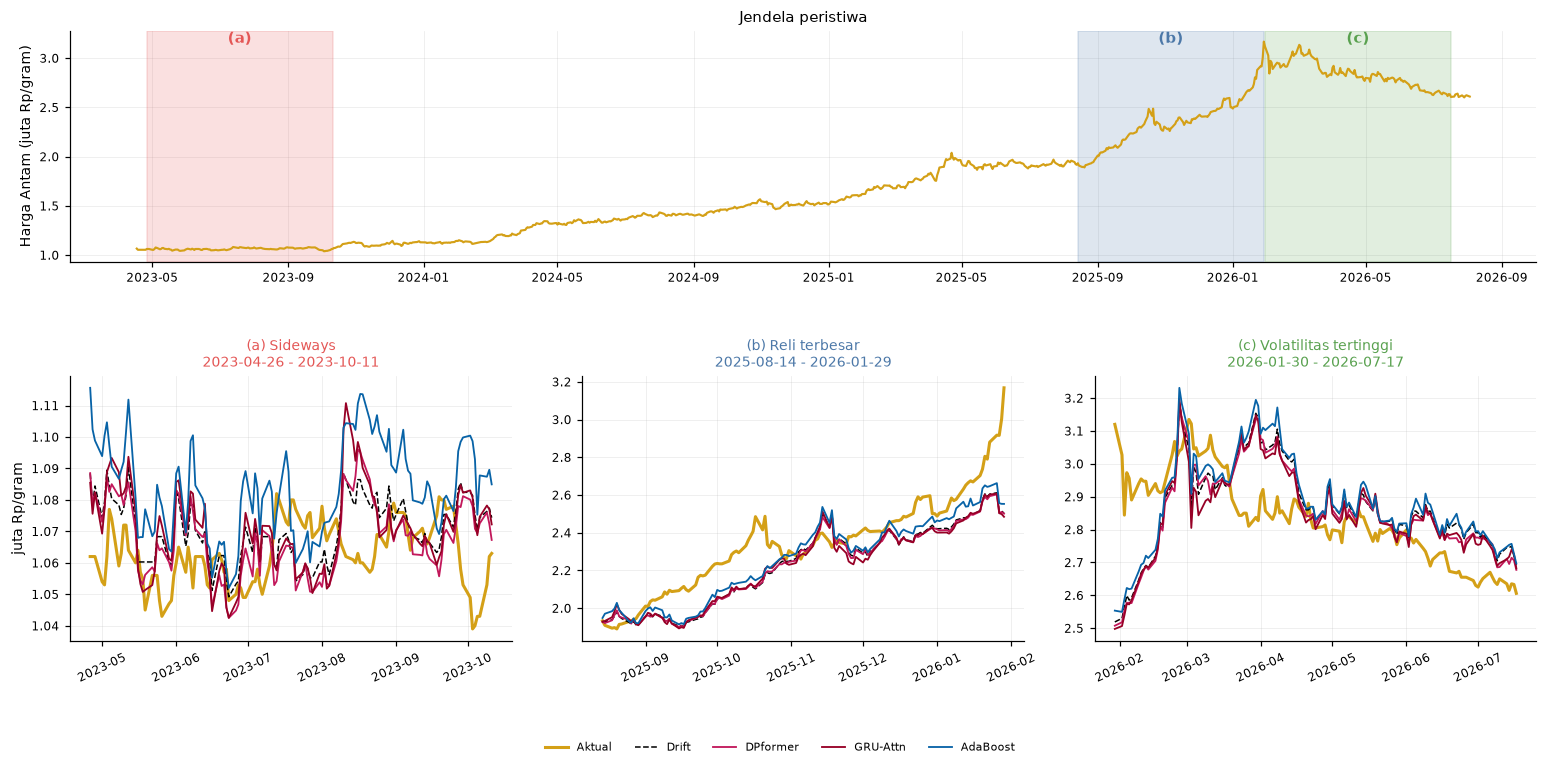

In [8]:
setup_ev = 'multivariat'
preds_ev = {m: A.attach(A.read_pred(RES, setup_ev, m, H_CURVE), fr[H_CURVE]) for m in reps3}
ev = A.choose_event_windows(p, preds_ev[wakil['dpformer']].index)
print(pd.DataFrame(ev))
cbe = []
for e in ev:
    sl = slice(e['mulai'], e['akhir'])
    cv = {'Aktual': fr[H_CURVE].y_true.loc[sl], 'drift': fr[H_CURVE].y_pred.loc[sl]}
    for m in reps3:
        cv[m] = preds_ev[m].y_pred.loc[sl]
    cbe.append(cv)
fig = P.fig_events(p, preds_ev[wakil['dpformer']].index, cbe, ev)
simpan(fig, 'fig_peristiwa')

### Cara membaca

- `mean_rank` lebih kecil = lebih konsisten; `pct_vs_drift > 0` = MAE lebih rendah dari Drift. **Jangan** menyebut model "unggul signifikan" hanya dari ranking atau selisih MAE — gunakan **notebook 10** (uji Diebold–Mariano, MCS) dan **notebook 12/16** (stabilitas antar-periode).
- Kurva prediksi yang tampak mengikuti aktual pada harga **level** sebagian besar karena harga hari ini sudah memuat hampir seluruh informasi (persistence): lihat panel return (b di `fig_panel_*`) dan `R2oos_vs_drift` untuk gambaran yang tidak menyesatkan.
- Hasil uji tidak dipakai untuk memilih ulang hiperparameter setelah notebook ini.